<a href="https://colab.research.google.com/github/daniswaramp/steel-rebar-corrosion-strength/blob/main/notebooks/corroded_steel_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, sys, shutil, subprocess, pathlib, urllib.request

IN_COLAB = "google.colab" in sys.modules
ON_KAGGLE = pathlib.Path("/kaggle/working").exists()
REPO_URL = "https://github.com/daniswaramp/corroded-steel-yield-force.git"
RAW = "https://raw.githubusercontent.com/daniswaramp/steel-rebar-corrosion-strength/main"
FILES = (("Data.csv", "data/Data.csv"), ("pipeline.py", "src/pipeline.py"))

if ON_KAGGLE:
    work = pathlib.Path("/kaggle/working/corroded-steel-yield-force")
    source = pathlib.Path("/kaggle/input/corroded-steel-yield-force-data")
elif IN_COLAB:
    work = pathlib.Path("/content/corroded-steel-yield-force")
    source = None
else:
    work = source = None

if work is not None:
    if not (work / "data" / "Data.csv").exists():
        if source is not None and (source / "Data.csv").exists():
            for name, rel in FILES:
                dest = work / rel
                dest.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(source / name, dest)
        else:
            try:
                subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(work)], check=True)
            except Exception as exc:
                print("clone failed, fetching the two files instead:", exc)
                for _, rel in FILES:
                    dest = work / rel
                    dest.parent.mkdir(parents=True, exist_ok=True)
                    urllib.request.urlretrieve(f"{RAW}/{rel}", dest)
    os.chdir(work)
    for pkg in ("shap", "lightgbm", "xgboost", "seaborn"):
        try:
            __import__(pkg)
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
    print("running in", "Colab" if IN_COLAB else "Kaggle")
    print("working directory:", os.getcwd())
    print("files:", sorted(os.listdir(".")))
else:
    print("local run: using the repository this notebook already sits in")



# Corroded steel bar yield force analysis: pitting-notch effects against uniform mass loss

This notebook works through a database of tensile tests on corroded reinforcing steel, collected from published experimental campaigns. Every row is one bar pulled to yield, and the question is what predicts how much load that bar still carries. I want to separate the part of the loss caused by even thinning from the part caused by a single deep pit, because the design formulas only see the mass that went missing.

## 1. The problem

Corroded reinforcement loses load capacity, and an engineer has to estimate that loss before anyone can trust a bar that is already in a structure. Design codes do it with one number, the mass loss, written as the original capacity times one minus a factor times the mass loss fraction.

That form assumes the metal left evenly. Chloride attack often does something else, because a pit is a notch. It concentrates stress in a small zone, local yielding starts there, and the bar reaches its limit at a load well below what its average section suggests. A straight line in mass loss cannot say that a deep narrow pit at 5 percent loss can be worse than even thinning at 10 percent, so the formula has no way to flag the bars that fail in service.


In [ ]:
import sys, pathlib, time, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# find the project root from wherever this notebook is launched
here = pathlib.Path.cwd()
cands = [here] + list(here.parents)
PROJ = next((p for p in cands
             if (p / "data" / "Data.csv").exists() and (p / "src" / "pipeline.py").exists()),
            here.parent)
sys.path.insert(0, str(PROJ / "src"))
from pipeline import load_data, build_features, run_pipeline, LAST

ACCENT, MUTED, INK = "#d55e00", "#9aa0a6", "#222222"
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.25,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "text.color": INK,
    "axes.labelcolor": INK,
})

df = load_data(PROJ / "data" / "Data.csv")
df["lnFy"] = np.log(df["Fy"].astype(float))
vc = df["Author"].value_counts()
thin = vc[vc < 10]
D = "Corrosion Penetration Depth"
M = "Mass Loss"

print(f"project root {PROJ}")
print(f"rows {df.shape[0]}, campaigns {df['Author'].nunique()}, columns after load {df.shape[1]}")
print(f"largest campaign {vc.index[0]} with {vc.iloc[0]} rows, {vc.iloc[0] / len(df) * 100:.1f} percent")
print(f"second largest {vc.index[1]} with {vc.iloc[1]}, smallest {vc.index[-1]} with {vc.iloc[-1]}")
print(f"campaigns under 10 rows: {len(thin)}, holding {thin.sum()} rows together")
print(f"Fy {df['Fy'].min():.2f} to {df['Fy'].max():.2f} kN, median {df['Fy'].median():.2f}")
print(f"ln(Fy) {df['lnFy'].min():.2f} to {df['lnFy'].max():.2f}")
print(f"mass loss {df[M].min():.1f} to {df[M].max():.1f} percent, median {df[M].median():.1f}, uncorroded rows {(df[M] == 0).sum()}")
print(f"penetration depth {df[D].min():.3f} to {df[D].max():.3f} mm, median {df[D].median():.2f}")
print(f"current density {df['Current Density'].min():.0f} to {df['Current Density'].max():.0f}, median {df['Current Density'].median():.0f}")
print(f"exposure duration {df['Exposure Duration'].min():.0f} to {df['Exposure Duration'].max():.0f}, median {df['Exposure Duration'].median():.0f}")
print(f"solution concentration values {sorted(df['Solution Concentration'].unique())}")
print(f"load history None {(df['Load_History'] == 'None').sum()} rows, cleaning method N/A {(df['Cleaning_Method'] == 'N/A').sum()} rows")
print(f"bar grade {df['Bar_Grade'].nunique()} labels, steel origin {df['Steel_Origin'].nunique()}, cathode {df['Cathode_Type'].nunique()}")


project root C:\Users\Safitri\Documents\1. Project Danis\Portfolio\Project 1\00. Steel Corrosion
rows 1349, campaigns 26, columns after load 22
largest campaign Matthews et al. (2023) with 284 rows, 21.1 percent
second largest Fernandez and Berrocal (2019) with 126, smallest Zhu and François (2014) with 5
campaigns under 10 rows: 6, holding 37 rows together
Fy 2.79 to 417.06 kN, median 90.88
ln(Fy) 1.03 to 6.03
mass loss 0.0 to 82.4 percent, median 8.1, uncorroded rows 174
penetration depth 0.000 to 2.678 mm, median 0.33
current density 0 to 4421, median 79
exposure duration 0 to 21915, median 114
solution concentration values [np.float64(0.0), np.float64(1.0), np.float64(3.0), np.float64(3.5), np.float64(5.0), np.float64(16.5)]
load history None 733 rows, cleaning method N/A 162 rows
bar grade 26 labels, steel origin 12, cathode 10


## 2. Challenges I had to work around

1. The target covers a wide range. Yield force runs from 2.79 kN to 417.06 kN here, a factor of 149, so I fit its logarithm rather than the force itself.

2. One campaign dominates the file. Matthews et al. (2023) supplies 284 of the 1,349 rows, 21.1 percent, and the second largest campaign supplies 126. Six campaigns hold fewer than 10 rows each. A random split would put the same campaign on both sides of the line, and the model would be reading its own answers back, so I report a campaign-grouped split as well.

3. The lab metadata mixes units and carries string labels that are not missing data. Solution concentration takes six values with no stated unit, current density runs from 0 to 4,421 against a median of 79, load history reads "None" in 733 rows, and cleaning method reads "N/A" in 162. Both strings are real categories that say something about the test, so the loader is told not to read them as gaps.

4. Pit depth is one number per bar. The column holds the deepest point measured on that bar, from 0 to 2.678 mm, and carries no count of pits, no spacing, and no shape. It stands in for notch geometry rather than being notch geometry.

5. Thinning and pitting are recorded together and never separately. Mass loss and penetration depth come from the same corroded bar, so no row lets me watch one move while the other stays still. Separating the two has to be done by construction instead of by waiting for a clean case.

## 3. What this notebook sets out to do

1. Fit the code formula as the bar to clear, with its degradation factor estimated from the data rather than assumed (Methods).
2. Rank six learners on one cross-validation pass and then on a held-out fifth of the file, in log units and in kN (How the models compare, Held-out results).
3. Plot the residuals of the code formula against pit depth beside the residuals of the fitted model (Where the code formula fails).
4. Price the pit-depth feature family by removing it and retraining the same learner (Removing the pit-depth family).
5. Hold mass loss fixed and vary only depth, so the notch effect can be seen on its own (Same mass loss, deeper pit).
6. Read the fitted model back through SHAP values, check that its predictive intervals mean what they claim, and measure how much of the score survives a split that keeps whole campaigns apart (What drives the prediction, Do the intervals mean what they claim, What survives an unseen campaign).


## 4. What the data holds

One row per tensile test, 1,349 in all, gathered from 26 campaigns. The database was compiled by Benjamin Matthews, Alessandro Palermo and Allan Scott for a predictive study of corroded steel, published in Construction and Building Materials in 2024 ([doi 10.1016/j.conbuildmat.2024.137023](https://doi.org/10.1016/j.conbuildmat.2024.137023)) and archived on Zenodo as [record 8035720](https://zenodo.org/records/8035720). The copy used here, and the fitting code that goes with it, comes from [bma114/corroded-steel-machine-learning](https://github.com/bma114/corroded-steel-machine-learning).

Sixteen columns describe the specimen. Eight are categorical: specimen type, load history, bar type, steel origin, bar grade, corrosion method, cathode type, cleaning method. Eight are numeric: nominal diameter, gauge length, current density, exposure duration, solution concentration, mass loss, corroded length, penetration depth. Fy and ln(Fy) are the outcomes, and the author column is split out of the specimen name so that campaigns can be grouped later.

Cleaning on this file is light. Column names are trimmed, the author name is separated from the specimen name, and every categorical cell is stripped and kept as a string so that "None" and "N/A" survive. No cell was blank and no numeric cell failed to parse, so no row was dropped and the file stays at 1,349. Bar grade carries 26 distinct labels and steel origin 12, which is why both go in as codes rather than as numbers.

## 5. Where the forces sit

I start with the target, because everything downstream depends on its shape. Each bar in the chart below counts how many tests land in one range of ln(Fy).

Fy quartiles in kN: 39.2, 90.9, 185.0
uncorroded controls: 174 rows, median force 118.6 kN
tests below 7.4 kN: 45, of them uncorroded: 0


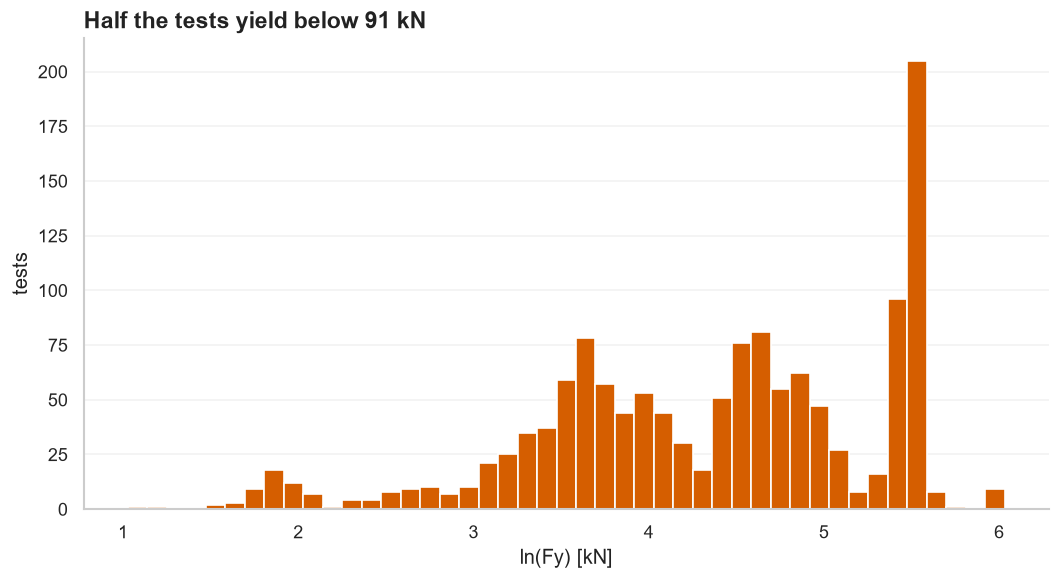

In [ ]:
chart, ax = plt.subplots()
ax.hist(df["lnFy"], bins=45, color=ACCENT, edgecolor="white")
ax.set_xlabel("ln(Fy) [kN]")
ax.set_ylabel("tests")
ax.set_title("Half the tests yield below 91 kN")
q = df["Fy"].quantile([0.25, 0.5, 0.75])
print(f"Fy quartiles in kN: {q.iloc[0]:.1f}, {q.iloc[1]:.1f}, {q.iloc[2]:.1f}")
ctrl = df[M] == 0
print(f"uncorroded controls: {int(ctrl.sum())} rows, median force {df.loc[ctrl, 'Fy'].median():.1f} kN")
print(f"tests below 7.4 kN: {int((df['Fy'] < 7.4).sum())}, of them uncorroded: {int(((df['Fy'] < 7.4) & ctrl).sum())}")
chart.tight_layout(); plt.show()


The middle half of the tests yield between 39.2 kN and 185.0 kN, with a median of 90.9 kN, and the log runs from 1.03 to 6.03. The 174 uncorroded controls sit in the upper middle at a median of 118.6 kN, which is where a code formula has to find its starting capacity.

Forty-five tests fall below 7.4 kN and none of them is a control. That low tail is corroded material, and it stretches the range far enough that fitting in force units would spend the model on the large bars.


## 6. Does mass loss order the strength

The code formula is a straight line in mass loss, so the first thing to test is whether the file behaves that way at all. Each dot is one test.


           tests  median_lnFy  iqr_lnFy  force_factor
Mass Loss                                            
0 to 2       264         4.65      1.01           2.7
2 to 5       193         4.84      1.42           4.1
5 to 10      366         4.97      1.43           4.2
10 to 20     324         4.31      1.17           3.2
above 20     202         3.41      1.37           3.9
rows binned 1349 of 1349


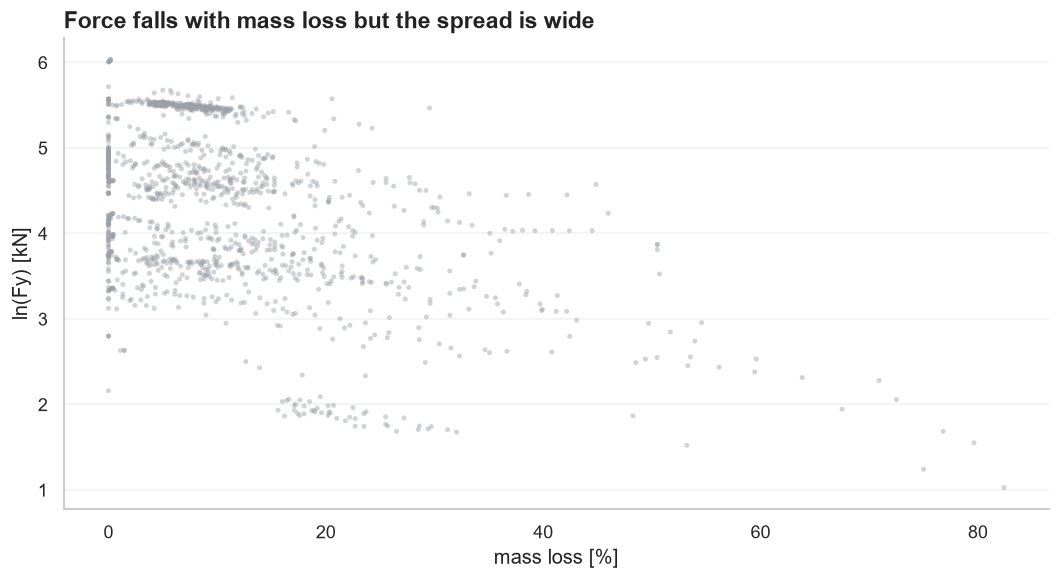

In [ ]:
chart, ax = plt.subplots()
ax.scatter(df[M], df["lnFy"], s=9, alpha=0.45, color=MUTED, edgecolor="none")
ax.set_xlabel("mass loss [%]")
ax.set_ylabel("ln(Fy) [kN]")
ax.set_title("Force falls with mass loss but the spread is wide")
cut = pd.cut(df[M], [-0.01, 2, 5, 10, 20, 100],
             labels=["0 to 2", "2 to 5", "5 to 10", "10 to 20", "above 20"])
grp = df.groupby(cut, observed=True)["lnFy"]
binsum = pd.DataFrame({
    "tests": grp.size(),
    "median_lnFy": grp.median().round(2),
    "iqr_lnFy": (grp.quantile(0.75) - grp.quantile(0.25)).round(2),
})
binsum["force_factor"] = np.exp(binsum["iqr_lnFy"]).round(1)
print(binsum.to_string())
print(f"rows binned {int(binsum['tests'].sum())} of {len(df)}")
chart.tight_layout(); plt.show()


Mass loss does not order the strength. The median ln(Fy) climbs from 4.65 in the 0 to 2 percent bin to 4.84, then to 4.97 in the 5 to 10 percent bin, before dropping to 4.31 at 10 to 20 percent and 3.41 above 20 percent. The 0 to 2 percent bin holds all 174 uncorroded controls, which is why it sits high.

The width matters more than the ordering. In the 5 to 10 percent bin the middle half of the tests spans 1.43 in ln(Fy), a factor of 4.2 in force. Mass loss at that level does not say how much load a bar will carry, and that gap is what the rest of the notebook is about.


## 7. Where the rows come from

Before fitting anything, I look at how the rows are spread over campaigns, because that decides how a split has to be made.

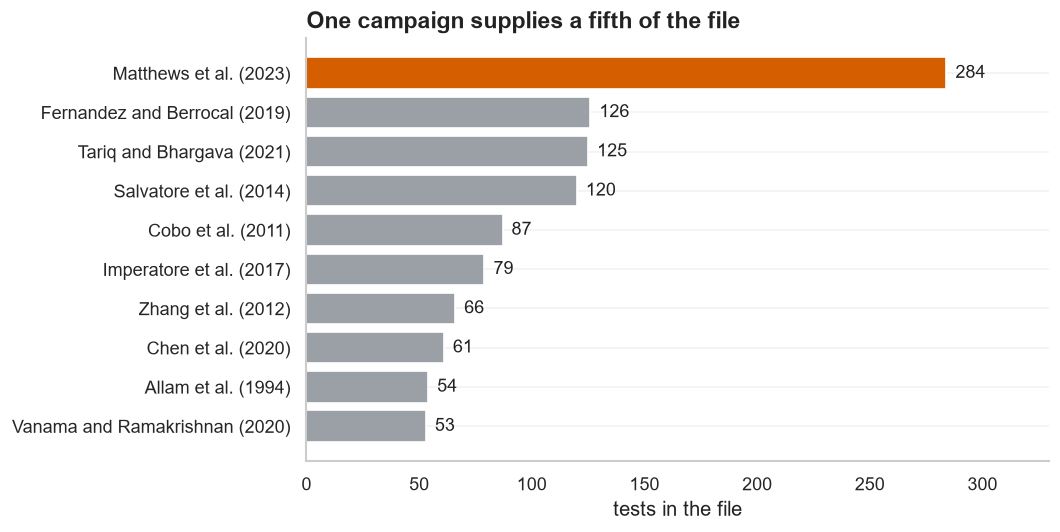

Matthews et al. (2023): 284 rows, 21.1 percent of 1349
campaigns under 10 rows: 6, rows together 37


In [ ]:
top = vc.head(10).sort_values()
chart, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(top.index, top.values,
        color=[ACCENT if name == top.index[-1] else MUTED for name in top.index])
ax.set_xlabel("tests in the file")
ax.set_title("One campaign supplies a fifth of the file")
for row, value in enumerate(top.values):
    ax.text(value + 4, row, str(value), va="center", fontsize=11, color=INK)
ax.set_xlim(0, top.max() * 1.16)
chart.tight_layout(); plt.show()
print(f"{vc.index[0]}: {vc.iloc[0]} rows, {vc.iloc[0] / len(df) * 100:.1f} percent of {len(df)}")
print(f"campaigns under 10 rows: {len(thin)}, rows together {thin.sum()}")


Matthews et al. (2023) supplies 284 rows, 21.1 percent of the file. The second largest supplies 126 and the smallest of all supplies 5. Six campaigns hold fewer than 10 rows each, 37 rows in total, so the grade and corrosion combinations that appear in those rows appear almost nowhere else.

This does not stop me modelling, but it decides how I report. A random split lets a model meet a campaign during training and meet it again at test time, which flatters the score. The last modelling section takes whole campaigns out to see what is left.

## 8. Does pit depth carry information of its own

Pooled across the whole file, penetration depth looks like a weak companion to force, and it is worth seeing why before trusting any model that uses it. Grey dots are every test, and the single colour marks the 395 tests on 16 mm bars, the largest group in the file.

correlation of depth with ln(Fy), all rows: -0.139
correlation of nominal diameter with ln(Fy): +0.907
diameter 10 mm: 159 tests, depth with ln(Fy) -0.824
diameter 12 mm: 156 tests, depth with ln(Fy) -0.801
diameter 16 mm: 395 tests, depth with ln(Fy) -0.604


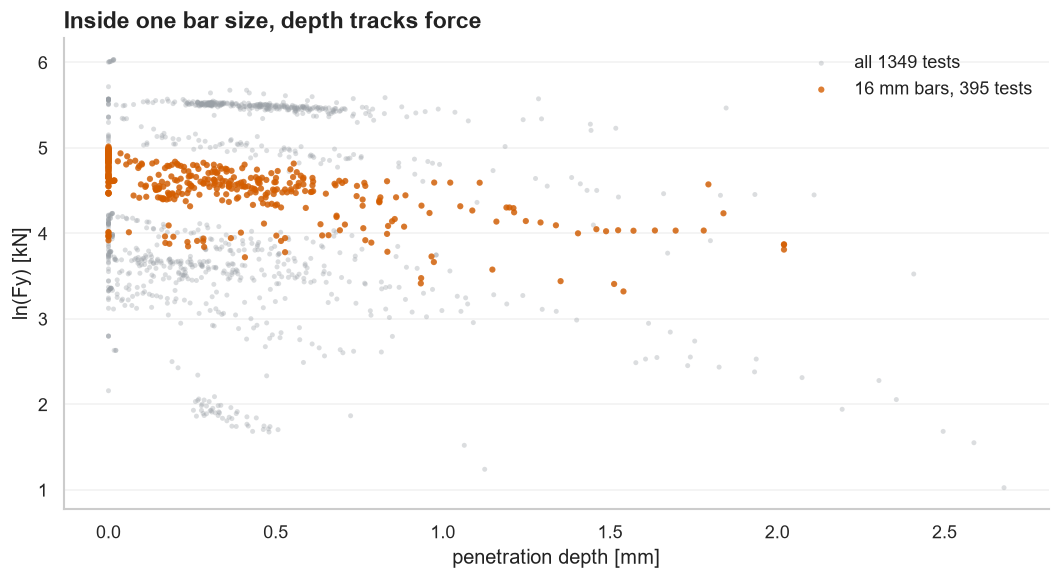

In [ ]:
SIZE = 16.0
one = (df["Nominal Diameter"] == SIZE).values
chart, ax = plt.subplots()
ax.scatter(df[D], df["lnFy"], s=9, alpha=0.35, color=MUTED, edgecolor="none",
           label=f"all {len(df)} tests")
ax.scatter(df[D].values[one], df["lnFy"].values[one], s=14, alpha=0.8, color=ACCENT,
           edgecolor="none", label=f"{SIZE:g} mm bars, {int(one.sum())} tests")
ax.set_xlabel("penetration depth [mm]")
ax.set_ylabel("ln(Fy) [kN]")
ax.set_title("Inside one bar size, depth tracks force")
ax.legend(frameon=False, fontsize=11)
dep_all = df[D].values
force_all = df["lnFy"].values
print(f"correlation of depth with ln(Fy), all rows: {np.corrcoef(dep_all, force_all)[0, 1]:+.3f}")
print(f"correlation of nominal diameter with ln(Fy): {np.corrcoef(df['Nominal Diameter'].values, force_all)[0, 1]:+.3f}")
for size in (10.0, 12.0, SIZE):
    sel = (df["Nominal Diameter"] == size).values
    print(f"diameter {size:g} mm: {int(sel.sum())} tests, "
          f"depth with ln(Fy) {np.corrcoef(dep_all[sel], force_all[sel])[0, 1]:+.3f}")
chart.tight_layout(); plt.show()


Across all 1,349 rows, depth correlates with ln(Fy) at -0.14, which reads as very little. Nominal diameter correlates at +0.91, so pooled force is mostly size and nothing else gets a look.

Hold the size still and the picture changes. Inside the 16 mm bars depth correlates at -0.60, inside the 12 mm bars at -0.80, and inside the 10 mm bars at -0.82. Depth is doing real work on bars of one size, and mixing sizes hides it. That is the reason the next section adds ratios instead of raw depths.


## 9. Features that speak about the notch

I keep the sixteen recorded columns and add six terms that describe mechanics rather than bookkeeping.

`eta` is mass loss as a fraction, the coordinate the code formula uses. `area_unif` is the fraction of section left under even thinning. `pit_depth_ratio` is depth over bar diameter, which is the form the correlation above says the model needs. `notch_severity` divides that ratio by the square root of eta, so a deep pit at low overall loss scores high and even thinning scores low. `log_current` and `log_exposure` are logs of the two skewed columns, because current density reaches 4,421 against a median of 79.

The categorical columns go in as ordinal codes. Five of the terms describe the pit, namely depth itself, the ratio, notch severity, and the two logs. That set is what I remove later to price what pitting knowledge is worth.

In [ ]:
X = build_features(df)
added = [c for c in X.columns if c not in df.columns]
print(f"features {X.shape[1]}: {X.shape[1] - len(added)} recorded columns plus {len(added)} added terms")
print("added terms:", added)
pd.DataFrame({
    "feature": X.columns,
    "median": [round(float(X[c].median()), 3) for c in X.columns],
    "max": [round(float(X[c].max()), 3) for c in X.columns],
})


features 22: 16 recorded columns plus 6 added terms
added terms: ['eta', 'area_unif', 'pit_depth_ratio', 'notch_severity', 'log_current', 'log_exposure']


,feature,median,max
0,Nominal Diameter,16.000,32.000
1,Gauge Length,200.000,641.000
2,Current Density,79.180,4421.000
3,Exposure Duration,114.000,21915.000
4,Solution Concentration,3.500,16.500
5,Mass Loss,8.100,82.400
6,Corroded Length,460.000,600.000
7,Corrosion Penetration Depth,0.330,2.678
8,eta,0.081,0.824
9,area_unif,0.919,1.000


## 10. Methods

The target is ln(Fy). Errors on a log read as proportional errors on force, and the log keeps a range from 2.79 kN to 417.06 kN in workable shape.

Two evaluations run side by side. One 10-fold cross-validation across all models gives the ranking, and an 80/20 split gives the figures. The test split is touched once. Seeds are fixed, so a re-run returns the same numbers. I report R2, RMSE and MAE on ln(Fy) and MAPE on force in kN, because a designer reads kN.

The baseline gets a fair fit rather than a convenient one. The starting capacity is the median control strength inside each grade and diameter group, and one global degradation factor is estimated by least squares over the training rows. That is the shape of a code calibration, and it is what the machine-learning models have to beat.

The learners are multiple linear regression as the floor, a random forest, XGBoost with a monotone decreasing constraint on the two mass-loss coordinates, LightGBM, a small neural network, and a Gaussian process with an isotropic composite kernel that also returns predictive intervals. I tried an automatic relevance determination kernel first and dropped it, since one fit on 1,200 points took over seven minutes and would have made the fold comparison impractical.

10-fold CV over all models ...


fitting all models on the train split ...


code-law baseline ...
pitting ablation: XGBoost with and without the pit-depth family ...


campaign-grouped split: 20 campaigns train, 6 unseen ...


figures ...



pipeline finished in 430.4 s

--------------------------------------------------------------------
Model                               R2      RMSE       MAE      MAPE
--------------------------------------------------------------------
MLR                             0.9596    0.2118    0.1448     15.52
RF                              0.9778    0.1569    0.0775      8.77
XGBoost                         0.9814    0.1438    0.0658       7.5
LightGBM                        0.9794    0.1513    0.0738      8.31
MLP                             0.9528    0.2289    0.1262     14.27
GPR                             0.9814    0.1435    0.0656      7.65
CodeLaw                          0.892    0.3462    0.1785     22.11
XGBoost_no_pit                  0.9802    0.1481    0.0658      7.59
XGBoost_grouped                 0.8204    0.3845    0.3028     37.82
--------------------------------------------------------------------
pipeline wall time 430 s


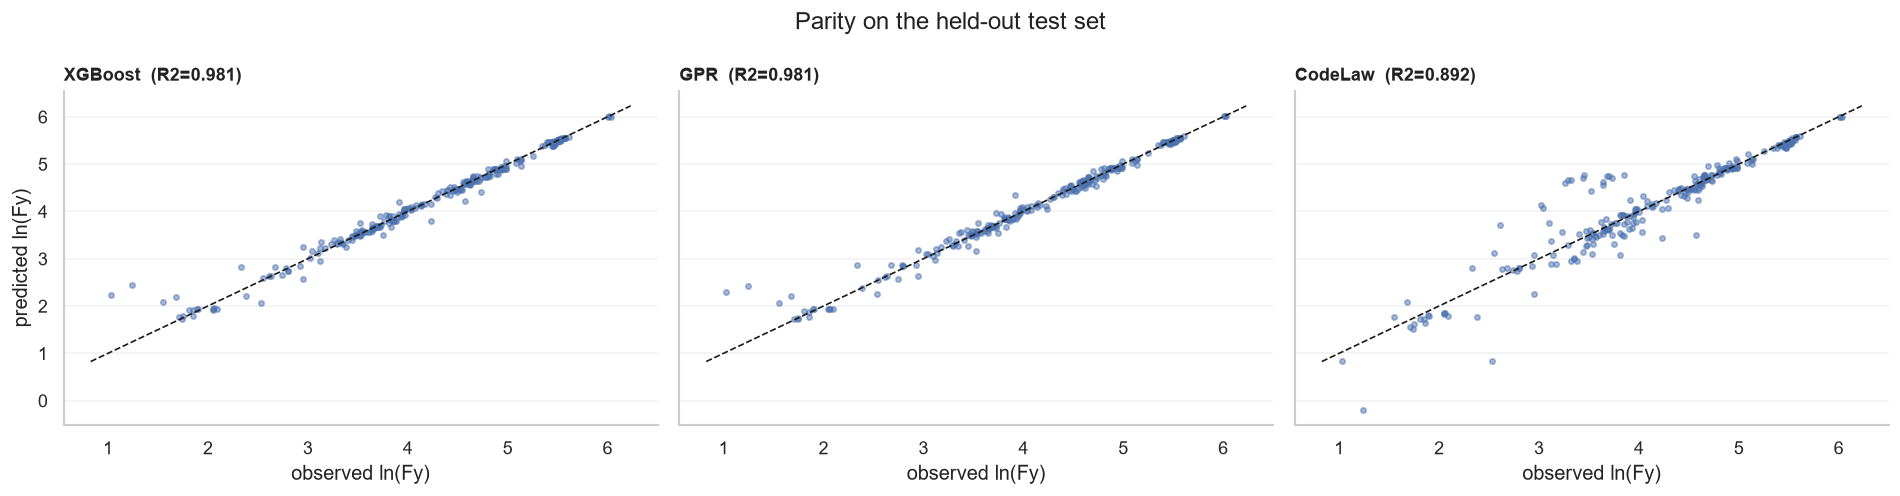

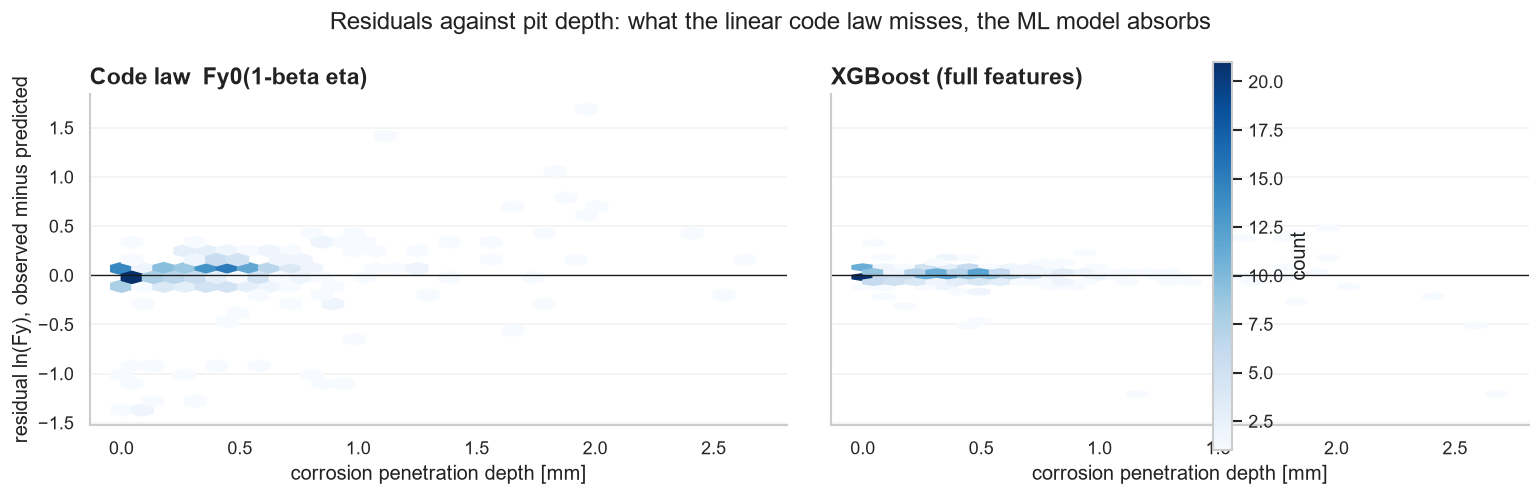

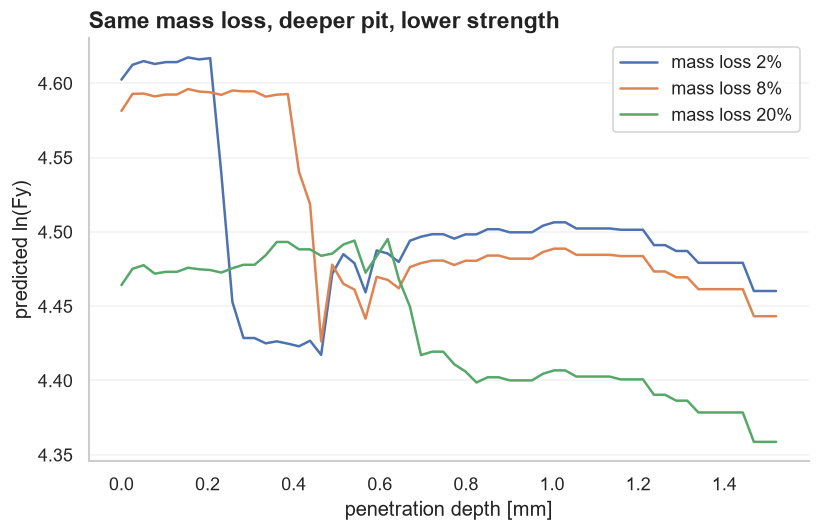

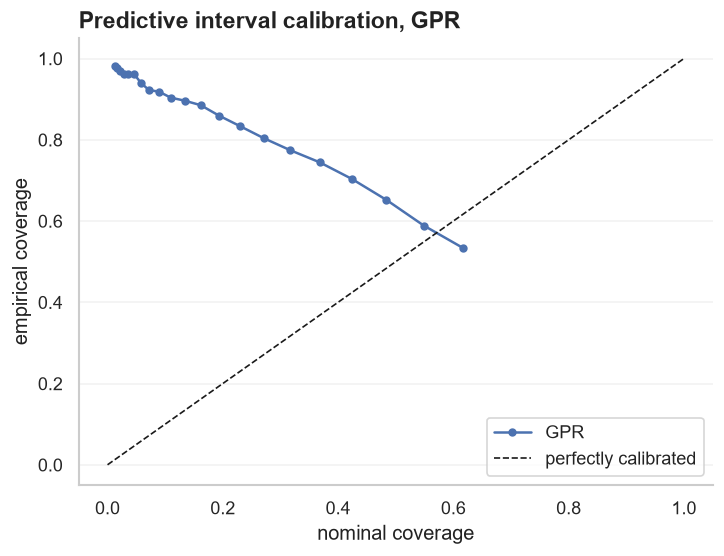

In [ ]:
from pipeline import print_table
results, elapsed = run_pipeline(df)
print(f"pipeline wall time {elapsed:.0f} s")


## 11. How the models compare

The first pass is cross-validation, where every model sees the same folds and the same inner split for early stopping.


In [ ]:
cv = pd.DataFrame(results["cv"]).T
cv[["R2_mean", "R2_std", "RMSE_mean"]].sort_values("R2_mean", ascending=False)
print(f"gap between XGBoost and GPR: {results['cv']['XGBoost']['R2_mean'] - results['cv']['GPR']['R2_mean']:.4f}")


gap between XGBoost and GPR: 0.0005


The top four finish within 0.005 of each other: XGBoost at R2 of 0.990, the Gaussian process at 0.989, LightGBM at 0.987, and the random forest at 0.986. The linear model comes last at 0.964, which says a straight line over all 22 features already reaches most of the way.

Cross-validation does not separate the leaders, so the choice among them has to come from somewhere else. I carry XGBoost and the Gaussian process forward and ask what each one gets wrong.

## 12. Held-out results

Cross-validation reuses the same rows many times, so I hold a fifth of the file back and touch it once.

In [ ]:
order = ["CodeLaw", "MLR", "RF", "XGBoost", "LightGBM", "MLP", "GPR",
         "XGBoost_no_pit", "XGBoost_grouped"]
rows = []
for name in order:
    v = results[name]
    rows.append({"model": name, "R2": v.get("R2"), "RMSE": v.get("RMSE"),
                 "MAE": v.get("MAE"), "MAPE_percent": v.get("MAPE"),
                 "PICP95": v.get("PICP95", "-"), "MPIW95": v.get("MPIW95", "-")})
held = pd.DataFrame(rows)
print(f"code law degradation factor {results['code_beta']}")
print(f"code law RMSE divided by XGBoost RMSE: {results['CodeLaw']['RMSE'] / results['XGBoost']['RMSE']:.2f}")
print(f"MAPE gap between them: {results['CodeLaw']['MAPE'] - results['XGBoost']['MAPE']:.2f} points")
held


code law degradation factor 1.602
code law RMSE divided by XGBoost RMSE: 2.41
MAPE gap between them: 14.61 points


,model,R2,RMSE,MAE,MAPE_percent,PICP95,MPIW95
0,CodeLaw,0.8920,0.3462,0.1785,22.11,-,-
1,MLR,0.9596,0.2118,0.1448,15.52,-,-
2,RF,0.9778,0.1569,0.0775,8.77,-,-
3,XGBoost,0.9814,0.1438,0.0658,7.50,-,-
4,LightGBM,0.9794,0.1513,0.0738,8.31,-,-
5,MLP,0.9528,0.2289,0.1262,14.27,-,-
6,GPR,0.9814,0.1435,0.0656,7.65,0.9593,0.3408
7,XGBoost_no_pit,0.9802,0.1481,0.0658,7.59,-,-
8,XGBoost_grouped,0.8204,0.3845,0.3028,37.82,-,-


The fitted code formula lands at R2 of 0.892 with a MAPE of 22.11 percent, and its degradation factor came out at 1.602, higher than the 1.0 that a pure area-loss reading would suggest. XGBoost reaches 0.981 with a MAPE of 7.50 percent, so its error in log units is 2.41 times smaller, a gap of 14.61 points of MAPE. The neural network and the linear model sit between the two, and the Gaussian process ties XGBoost on R2 while also returning intervals.

A factor of 1.602 is the formula already hearing about damage that mass loss does not carry, because mass loss is itself a poor stand-in for the section lost to pitting. It still costs 14.61 points of MAPE against the tree models, and the next section looks at where that cost sits.


## 13. Where the code formula fails

An aggregate score hides where a model goes wrong, so I plot predicted against observed for the code formula, XGBoost and the Gaussian process on the same held-out rows. Each dot is one test and the dashed line is perfect agreement.

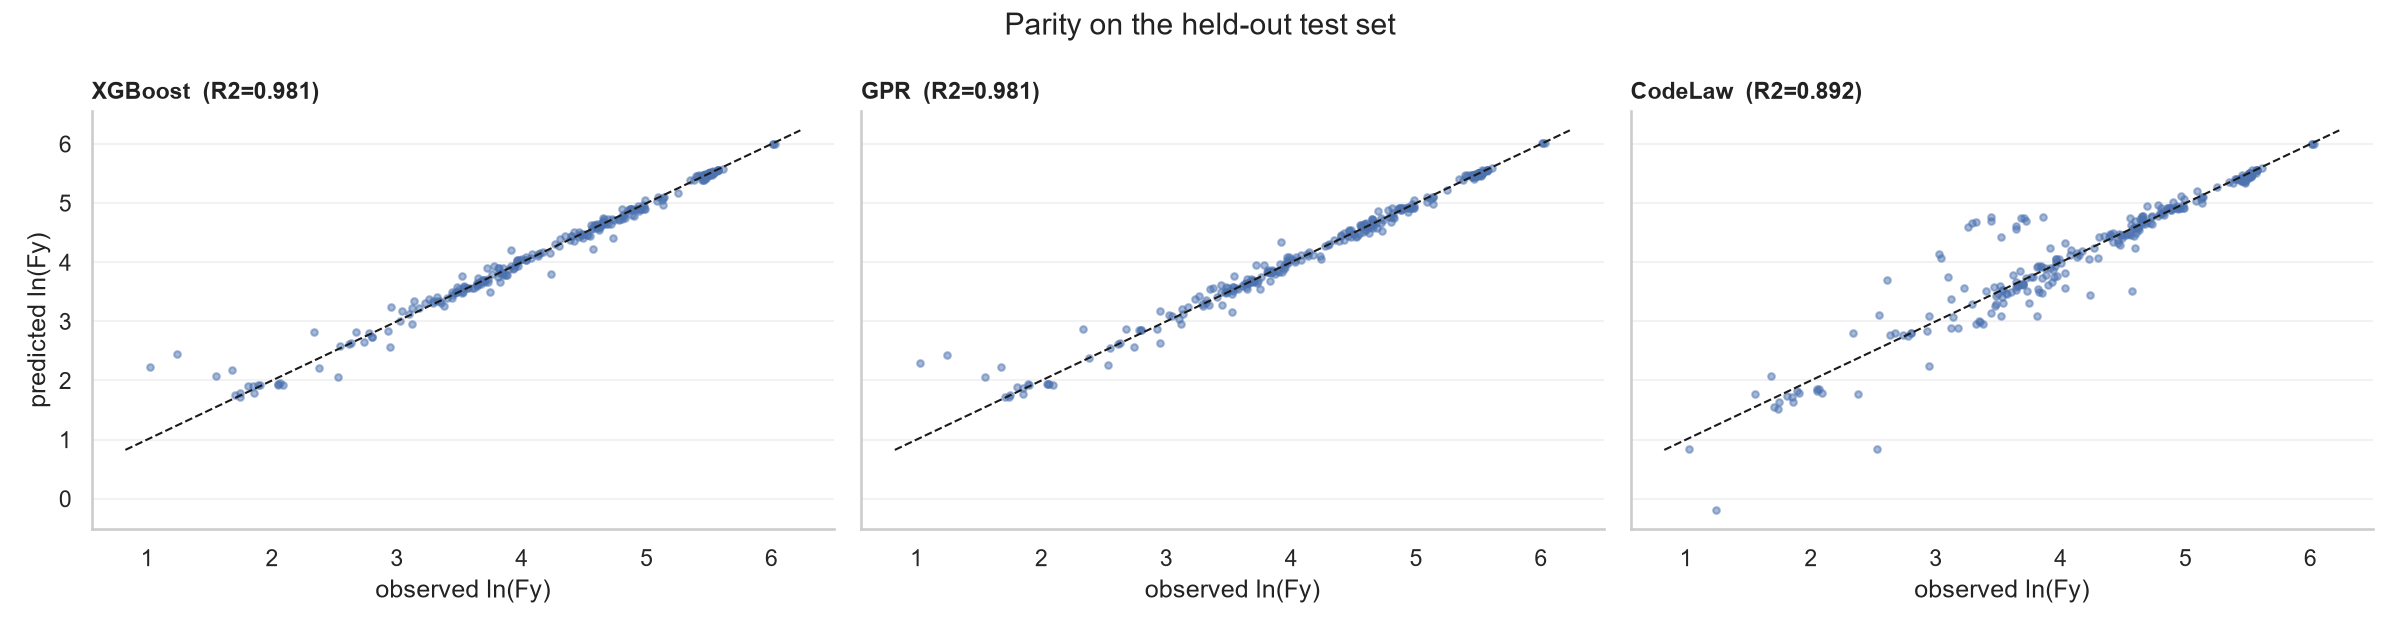

In [ ]:
from IPython.display import Image as Img, display
display(Img(filename=str(PROJ / "figures" / "parity.png"), width=950))


The code formula tracks the middle of the cloud and misses at both ends, which is what a straight line does when the truth curves. Its points scatter well off the diagonal where XGBoost and the Gaussian process sit tight against it, and those two agree with each other to within 0.0001 of R2. Agreement between them is the expected part. The disagreement is what I came for, and it has a shape: it grows with pit depth.

The same held-out rows again, now as residuals, observed minus predicted, against pit depth. The code formula is on the left and XGBoost on the right. Each dot is one test and the shading counts how many dots share a cell.


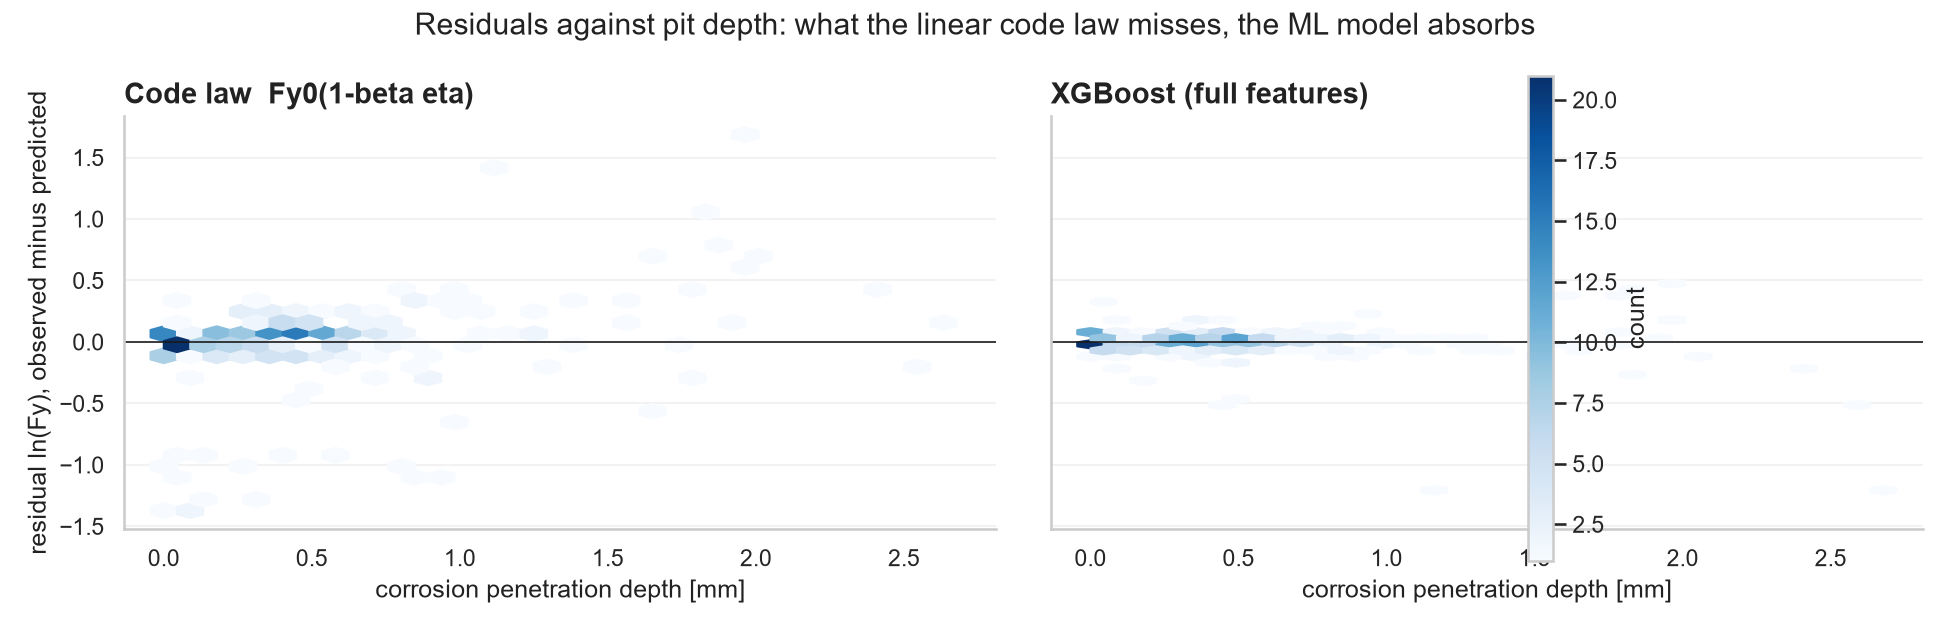

             tests  code_mean  code_mean_abs  xgb_mean_abs
bin                                                       
0 to 0.25       56     -0.127          0.179         0.045
0.25 to 0.5     87     -0.001          0.126         0.055
0.5 to 1.0      67     -0.019          0.186         0.044
1.0 to 1.5      11      0.235          0.271         0.142
1.5 to 3.0      16      0.389          0.531         0.278
correlation of depth with the code law residual: +0.308
correlation of depth with the XGBoost residual: -0.179
tests with depth at or above 1.0 mm: 27, code law mean abs 0.425, XGBoost mean abs 0.222


In [ ]:
display(Img(filename=str(PROJ / "figures" / "notch_residuals.png"), width=950))
yt = LAST["y_test"]
dtest = LAST["df_test"]
depth = dtest[D].values
code_resid = yt - LAST["preds"]["CodeLaw"]
xgb_resid = yt - LAST["preds"]["XGBoost"]
cut = pd.cut(depth, [0, 0.25, 0.5, 1.0, 1.5, 3.0],
             labels=["0 to 0.25", "0.25 to 0.5", "0.5 to 1.0", "1.0 to 1.5", "1.5 to 3.0"])
g = pd.DataFrame({"bin": cut, "code": code_resid, "xgb": xgb_resid}).groupby("bin", observed=True)
resid = pd.DataFrame({
    "tests": g.size(),
    "code_mean": g["code"].mean().round(3),
    "code_mean_abs": g["code"].apply(lambda s: float(np.abs(s).mean())).round(3),
    "xgb_mean_abs": g["xgb"].apply(lambda s: float(np.abs(s).mean())).round(3),
})
print(resid.to_string())
print(f"correlation of depth with the code law residual: {np.corrcoef(depth, code_resid)[0, 1]:+.3f}")
print(f"correlation of depth with the XGBoost residual: {np.corrcoef(depth, xgb_resid)[0, 1]:+.3f}")
deep = depth >= 1.0
print(f"tests with depth at or above 1.0 mm: {int(deep.sum())}, "
      f"code law mean abs {np.abs(code_resid[deep]).mean():.3f}, XGBoost mean abs {np.abs(xgb_resid[deep]).mean():.3f}")


The left panel carries a bias that grows with depth, and the table under the chart measures it. In the shallowest bin, up to 0.25 mm of pit, the code law's mean residual is -0.127, so it overstates the force on bars that are close to sound. In the deepest bin, from 1.5 to 3.0 mm, the mean residual is +0.389, so it understates them by a factor of about 1.5. Depth and the code law's error correlate at +0.308.

The direction surprised me, so it is worth stating plainly. A formula that cannot see a pit at all should be optimistic on the deeply pitted bars, and on this sample it is conservative there instead, while being optimistic on the sound ones. What the numbers do support is that the error grows with depth, from a mean absolute 0.179 in the shallowest bin to 0.531 in the deepest. The 27 held-out tests with a pit of 1.0 mm or more carry a mean absolute error of 0.425 for the formula against 0.222 for XGBoost, close to double, and XGBoost's own residuals show no such trend at -0.179 against the same depth.

## 14. Removing the pit-depth family

I take depth, the depth ratio, notch severity, and the two log exposure terms out of the feature set and retrain the same learner on the same folds. Nothing else changes.

In [ ]:
full, nopit = results["XGBoost"], results["XGBoost_no_pit"]
print(f"with the pit family:    R2 {full['R2']:.4f}, RMSE {full['RMSE']:.4f}, MAPE {full['MAPE']:.2f} percent")
print(f"without the pit family: R2 {nopit['R2']:.4f}, RMSE {nopit['RMSE']:.4f}, MAPE {nopit['MAPE']:.2f} percent")
print(f"R2 gap {full['R2'] - nopit['R2']:.4f}, "
      f"RMSE increase {(nopit['RMSE'] / full['RMSE'] - 1) * 100:.1f} percent, "
      f"MAPE difference {nopit['MAPE'] - full['MAPE']:.2f} points")


with the pit family:    R2 0.9814, RMSE 0.1438, MAPE 7.50 percent
without the pit family: R2 0.9802, RMSE 0.1481, MAPE 7.59 percent
R2 gap 0.0012, RMSE increase 3.0 percent, MAPE difference 0.09 points


The gap is small: 0.0012 in R2 and a 3.0 percent rise in RMSE, worth 0.09 points of MAPE. Mass loss and diameter already explain most of the variance, so depth has little room left to add to a score averaged over every row.

That average is the wrong place to look for damage, because failures are local, and the cost of removing the family is not spread evenly across the sample. The ablation itself does not say which rows pay, so I hold mass loss still and move only the depth to see the effect directly.

## 15. Same mass loss, deeper pit

Each curve below holds mass loss fixed at 2, 8, or 20 percent and varies only penetration depth, with every other feature set to its median value for the training split. Nothing else moves along a curve, so whatever happens inside it is the depth effect on its own.


median bar diameter in the training split: 16.0 mm


mass loss  2 percent: predicted ln(Fy) 4.602 at no pit and 4.460 at 1.52 mm, a fall of 0.142 log units. Largest single drop -0.087 at 0.26 mm.
mass loss  8 percent: predicted ln(Fy) 4.581 at no pit and 4.443 at 1.52 mm, a fall of 0.138 log units. Largest single drop -0.092 at 0.46 mm.
mass loss 20 percent: predicted ln(Fy) 4.464 at no pit and 4.359 at 1.52 mm, a fall of 0.105 log units. Largest single drop -0.033 at 0.70 mm.


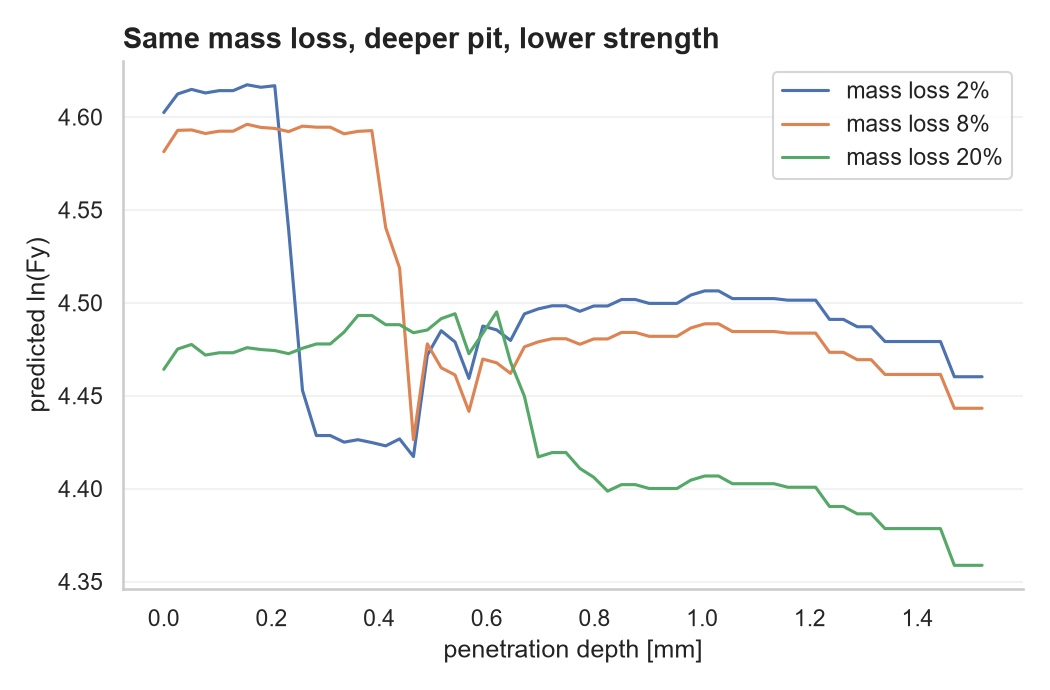

In [ ]:
from sklearn.model_selection import train_test_split
X_train, _, _, _ = train_test_split(X, df, test_size=0.2, random_state=42)
model = LAST["models"]["XGBoost"]
med = X_train.median()
grid = np.linspace(0, float(X_train[D].quantile(0.98)), 60)
print(f"median bar diameter in the training split: {med['Nominal Diameter']:.1f} mm")
for ml in (2, 8, 20):
    probe = pd.DataFrame([med] * len(grid))
    probe[D] = grid
    probe[M] = ml
    eta = float(np.clip(ml / 100, 0, 0.95))
    diam = probe["Nominal Diameter"].clip(lower=1e-6).values
    probe["eta"] = eta
    probe["area_unif"] = 1 - eta
    probe["pit_depth_ratio"] = grid / diam
    probe["notch_severity"] = (grid / diam) / np.sqrt(eta + 0.005)
    pred = model.predict(probe)
    step = np.diff(pred)
    where = int(np.argmin(step))
    print(f"mass loss {ml:>2} percent: predicted ln(Fy) {pred[0]:.3f} at no pit and {pred[-1]:.3f} at "
          f"{grid[-1]:.2f} mm, a fall of {pred[0] - pred[-1]:.3f} log units. "
          f"Largest single drop {step[where]:.3f} at {grid[where + 1]:.2f} mm.")
display(Img(filename=str(PROJ / "figures" / "pd_depth.png"), width=640))


All three curves fall as depth grows, which is the sign I was looking for, but the size is modest. At 2 percent loss the predicted force drops 0.142 in ln(Fy) between no pit and 1.52 mm of pit, about 13 percent in force. At 8 percent the fall is 0.138 and at 20 percent it is 0.105.

The shape is a threshold rather than a smooth slope. The largest single drop lands at 0.26 mm for 2 percent loss, 0.46 mm for 8 percent, and 0.70 mm for 20 percent, so the pit has to go deeper before the prediction reacts when more metal has already gone. A model that knew only mass loss would draw these as flat lines.

I read the size honestly. A 0.142 drop is real, it holds at all three loss levels, and it agrees with the residual bias and with the ablation gap, but it is not what separates a usable model from an unusable one. The grouped split later in the notebook moves the score far more.

## 16. What drives the prediction

SHAP values split each prediction into the contribution of every feature, so I can see which columns carry the weight. Each dot is one held-out test. The horizontal axis is the feature value, the vertical axis is how much that value moved the prediction, and colour marks the value itself.

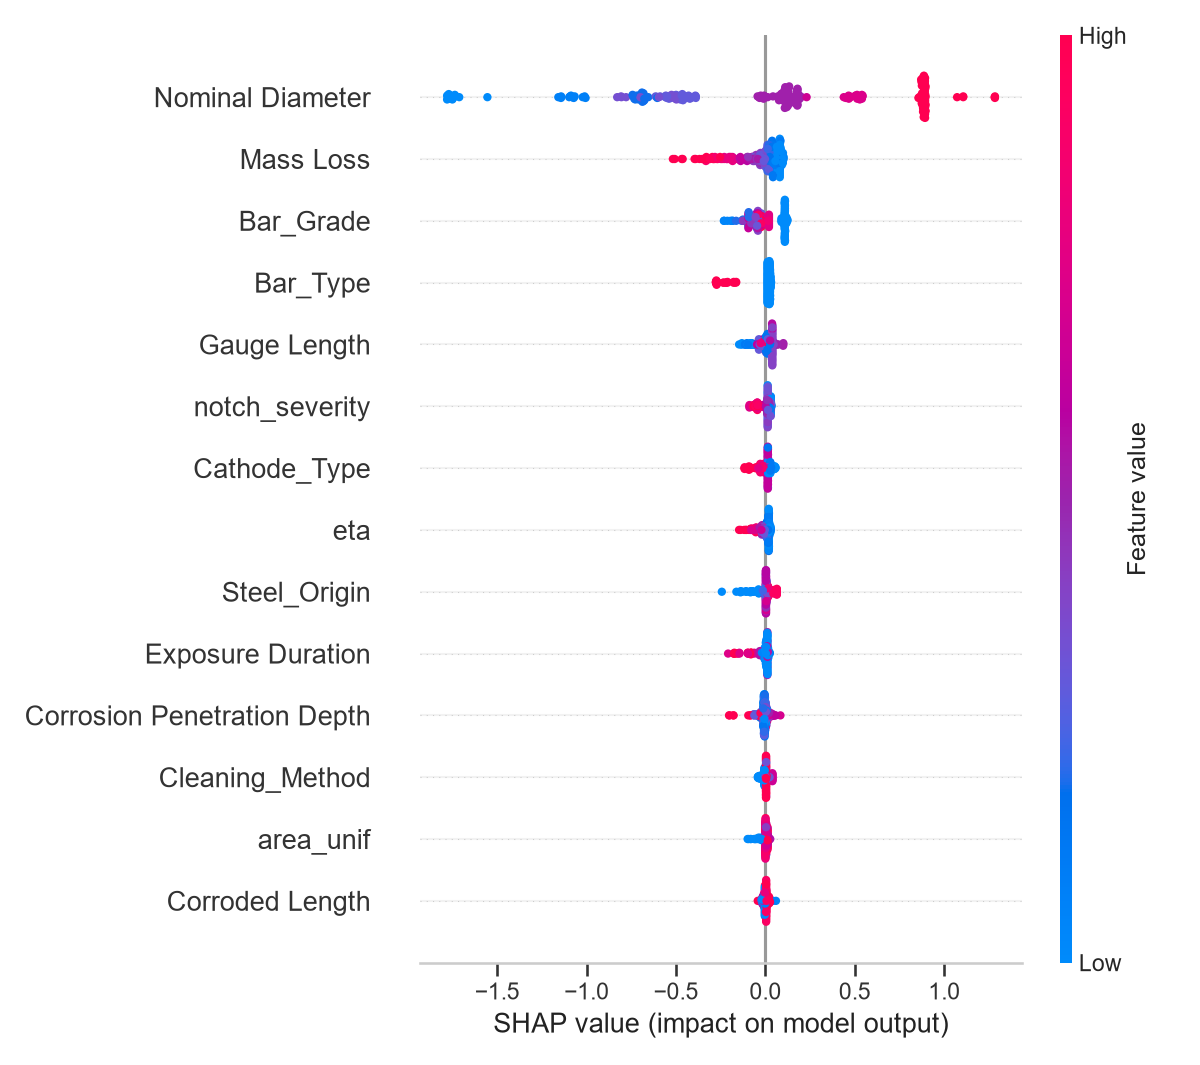

In [ ]:
display(Img(filename=str(PROJ / "figures" / "shap_xgb.png"), width=850))


Nominal diameter dominates the chart, and its dots spread from about -1.6 to +1.1, far wider than anything else. Mass loss comes second and spreads roughly from -0.5 to 0.0. Bar grade follows, then bar type and gauge length, which is size and steel strength doing what the correlations in section 8 said they would.


The next three charts show how the individual terms enter a prediction, coloured by mass loss, penetration depth, or bar grade so that the interaction is visible.


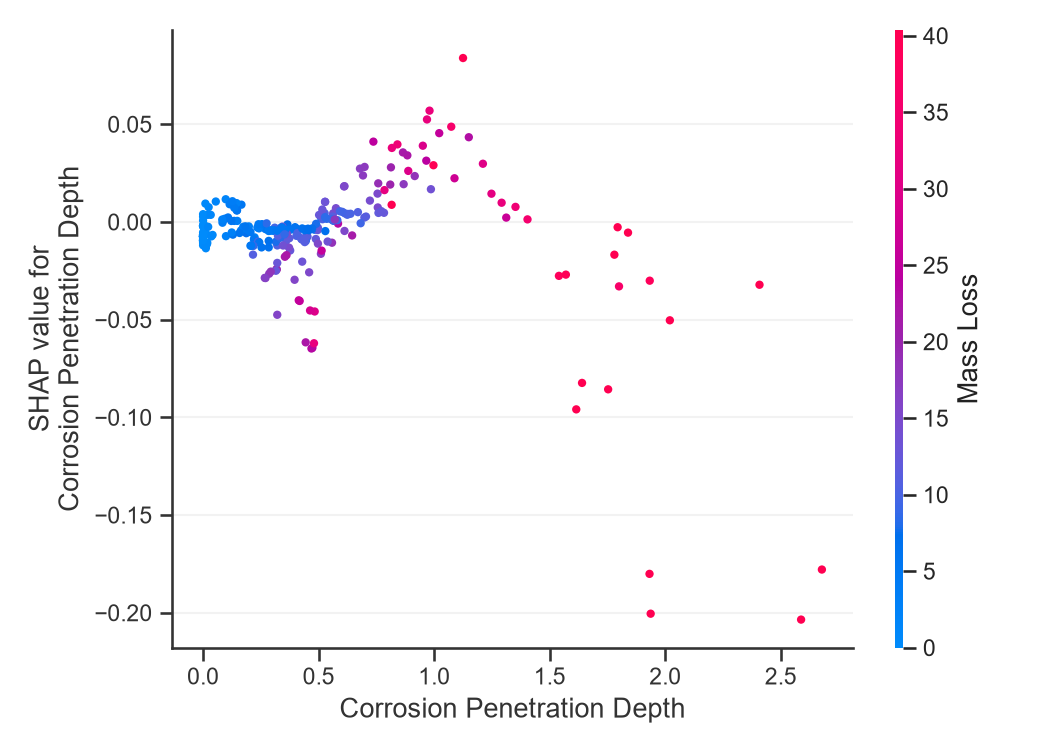

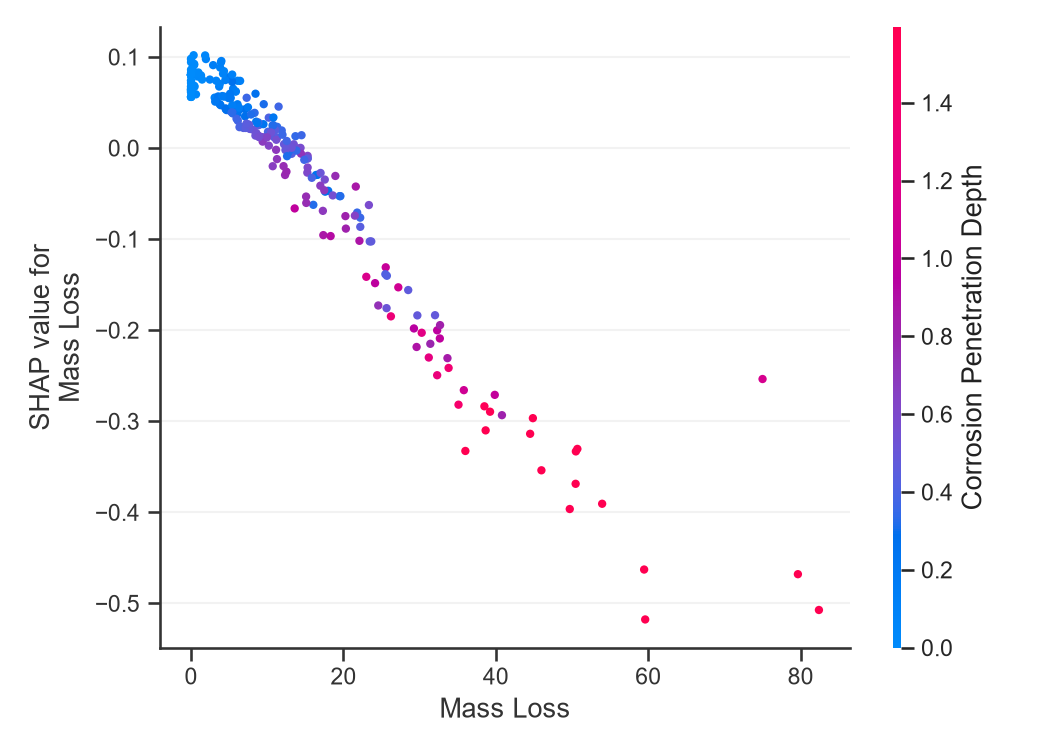

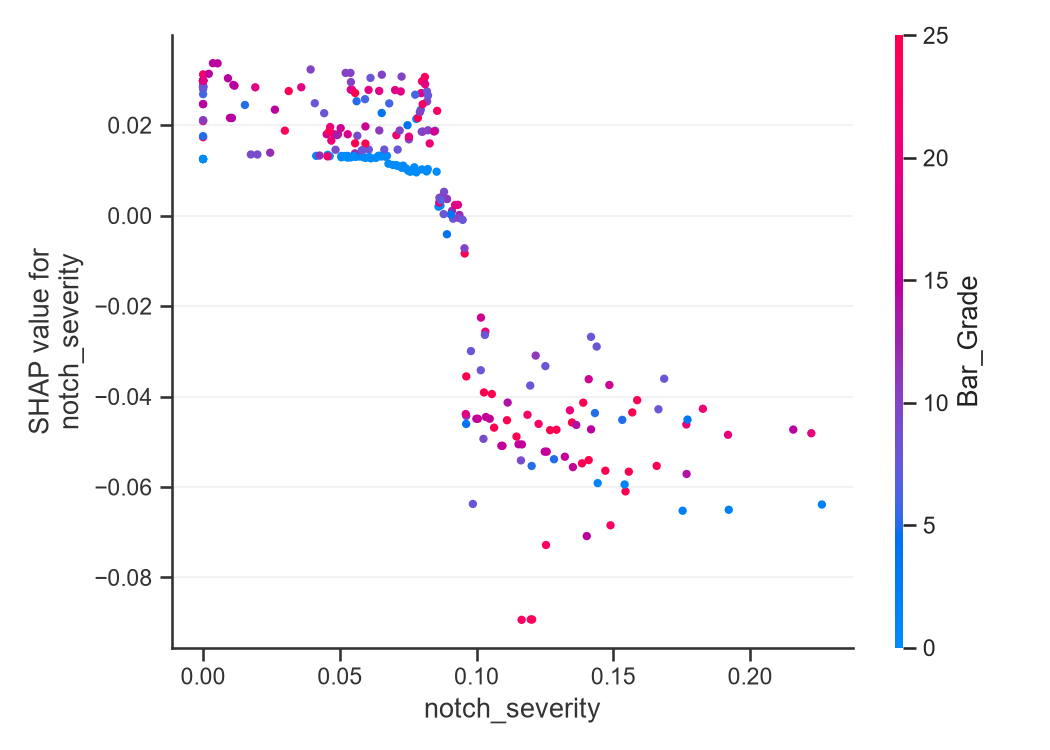

In [ ]:
for shot in sorted((PROJ / "figures").glob("shap_dep_*.png")):
    display(Img(filename=str(shot), width=520))


Mass loss moves the prediction from about +0.09 with nothing lost to -0.51 at 82 percent loss, and the deepest pits sit at the high end of that range, so thinning and pitting arrive together. Penetration depth stays near zero below 1.0 mm, rises to +0.07 around 0.9 mm at mid mass loss, and then falls below -0.05 past 1.6 mm, reaching -0.20 at 2.5 mm. Notch severity steps down once it passes 0.09, from about +0.03 to -0.05 and lower.

So both pit terms act in the deep range and do almost nothing in the shallow range, which is the same part of the depth axis where the code law's residual bias sits.


The same information as a table, since a chart is awkward to quote. Weights are mean absolute SHAP values, and the share column divides each one by the total of the fourteen listed.


In [ ]:
top = pd.DataFrame(results["shap_top"], columns=["feature", "mean_abs_shap"])
total = float(top["mean_abs_shap"].sum())
top["share_percent"] = (top["mean_abs_shap"] / total * 100).round(1)
top["cumulative_percent"] = top["share_percent"].cumsum().round(1)
print(f"total weight across the {len(top)} listed features: {total:.4f}")
print(top.to_string(index=False))


total weight across the 14 listed features: 0.9880


                    feature  mean_abs_shap  share_percent  cumulative_percent
           Nominal Diameter         0.6146           62.2                62.2
                  Mass Loss         0.0820            8.3                70.5
                  Bar_Grade         0.0633            6.4                76.9
                   Bar_Type         0.0387            3.9                80.8
               Gauge Length         0.0316            3.2                84.0
             notch_severity         0.0269            2.7                86.7
               Cathode_Type         0.0252            2.6                89.3
                        eta         0.0226            2.3                91.6
               Steel_Origin         0.0194            2.0                93.6
          Exposure Duration         0.0189            1.9                95.5
Corrosion Penetration Depth         0.0157            1.6                97.1
            Cleaning_Method         0.0112            1.1      

Nominal diameter accounts for 62.2 percent of the total weight and mass loss for 8.3 percent, so the two together account for 70.5 percent. Notch severity holds 2.7 percent and penetration depth 1.6 percent, which is small next to diameter and still a large share of what is left once size and thinning are accounted for.


## 17. Do the intervals mean what they claim

The Gaussian process returns a standard deviation with every prediction, so I can ask whether a 95 percent band really covers 95 percent of the held-out rows. The chart plots the coverage I asked for against the coverage I got, against the diagonal that a perfect model would follow.

PICP95 = 0.959 against a target of 0.95
MPIW95 = 0.341 log units against an RMSE of 0.143
average band is 2.37 times the RMSE


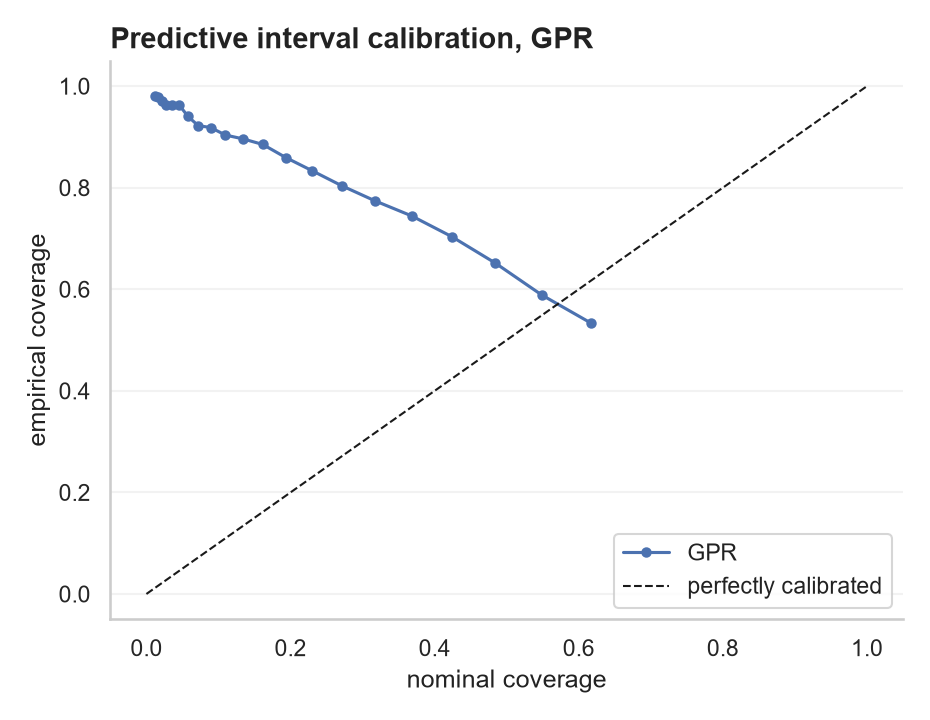

In [ ]:
g = results["GPR"]
print(f"PICP95 = {g['PICP95']:.3f} against a target of 0.95")
print(f"MPIW95 = {g['MPIW95']:.3f} log units against an RMSE of {g['RMSE']:.3f}")
print(f"average band is {g['MPIW95'] / g['RMSE']:.2f} times the RMSE")
display(Img(filename=str(PROJ / "figures" / "calibration.png"), width=540))


Coverage comes out at 0.959 against a target of 0.95, so the intervals are close to honest and lean a little toward being too wide. The average band is 0.341 in log units, 2.37 times the RMSE of 0.143, which is what a 95 percent claim costs on an error distribution of that shape.

I would not quote a single bar's band without that check. A mean coverage of 0.959 says nothing about how the errors are distributed, so the curve matters as much as the number.

## 18. What survives an unseen campaign

A lab applying this to its own new test programme faces campaigns that are not in the file. I retrain XGBoost on roughly three quarters of the campaigns and test on the rest, so no campaign appears on both sides.

In [ ]:
grp_res = results["XGBoost_grouped"]
print(f"random split:  R2 {results['XGBoost']['R2']:.4f}, RMSE {results['XGBoost']['RMSE']:.4f}, "
      f"MAPE {results['XGBoost']['MAPE']:.2f} percent")
print(f"grouped split: R2 {grp_res['R2']:.4f}, RMSE {grp_res['RMSE']:.4f}, "
      f"MAPE {grp_res['MAPE']:.2f} percent")
print(f"R2 falls by {results['XGBoost']['R2'] - grp_res['R2']:.4f}, "
      f"MAPE grows by a factor of {grp_res['MAPE'] / results['XGBoost']['MAPE']:.2f}")


random split:  R2 0.9814, RMSE 0.1438, MAPE 7.50 percent
grouped split: R2 0.8204, RMSE 0.3845, MAPE 37.82 percent
R2 falls by 0.1610, MAPE grows by a factor of 5.04


R2 falls from 0.981 to 0.820 and the MAPE grows from 7.50 to 37.82 percent, five times worse. Campaigns differ in steel source, corrosion set-up, and cleaning method, and the file records some of that but not all of it, so a model that has already met a campaign has an easier job than one that has not.

The number to quote outside this notebook is 0.820, not 0.981.


## 19. What I found

Mass loss on its own does not order the strength in this file. The median ln(Fy) climbs from 4.65 in the 0 to 2 percent bin to 4.97 in the 5 to 10 percent bin before falling to 3.41 above 20 percent, and inside that 5 to 10 percent bin the middle half of the tests spans a factor of 4.2 in force.

Penetration depth carries information that the pooled view hides. Its correlation with ln(Fy) is -0.14 across all rows, -0.60 inside the 16 mm bars and -0.80 inside the 12 mm bars, with diameter itself at +0.91.

A code formula fitted properly reaches R2 of 0.892 and a MAPE of 22.11 percent, with a degradation factor of 1.602. XGBoost reaches 0.981 and a MAPE of 7.50 percent on the same held-out fifth, with an error 2.41 times smaller in log units.

The formula's error grows with pit depth while the fitted model's does not. Its mean residual runs from -0.127 in the shallowest depth bin to +0.389 in the deepest, so it overstates sound bars and understates the most pitted ones, and the 27 held-out tests with a pit of 1.0 mm or more give it a mean absolute error of 0.425 against 0.222 for XGBoost. Removing the five pit-depth features costs 0.0012 in R2 and 3.0 percent of RMSE, and predicted force at fixed mass loss falls by 0.142 in log units between no pit and 1.52 mm of pit.

Size and mass loss carry the predictions. Nominal diameter holds 62.2 percent of the SHAP weight across the fourteen features listed and mass loss 8.3 percent. The Gaussian process intervals cover 0.959 of the held-out rows against a 0.95 target.

The portability number is much lower than the headline. Holding whole campaigns out gives R2 of 0.820 and a MAPE of 37.82 percent, against 0.981 and 7.50 percent on the random split.

## 20. What I could not tell

I cannot say how portable the model is to a campaign that does not exist yet. Six campaigns held out cost 0.161 of R2 and multiplied the MAPE by five, and the gap left over after that is unmeasured rather than small.

I cannot say what the pits looked like. Penetration depth is a single number per bar, the deepest point, running from 0 to 2.678 mm, with no count, no spacing, and no shape. A bar with ten shallow pits and a bar with one deep pit can carry the same number here.

I cannot see ductility. The file holds yield force only, so the loss of elongation that pitting causes is invisible to every model in this notebook, and that is the failure mode engineers meet in the field.

I cannot tell which rows are accelerated laboratory tests and which are natural exposure. Current density reaches 4,421 against a median of 79, and at the extreme end the corrosion may not resemble chloride pitting in a structure. Nothing in the file separates the two beyond the recorded current density.

I cannot place the six campaigns with fewer than 10 rows. They carry 37 rows in total, and their grade and corrosion combinations appear nowhere else in the sample, so whatever they contribute is carried by a handful of tests.

## 21. What I would do next

I would make the campaign-grouped split the default protocol and report cross-validation by group, so that no score in this work depends on a campaign appearing on both sides. A hierarchical fit with campaign random effects would use the six small campaigns instead of leaving them in the noise.

I would replace the depth column with profilometry or 3D scan data: pit count, pit spacing, a shape factor, and a notch stress concentration computed from the geometry by finite element analysis. The depth ratio would then be a check rather than a stand-in.

I would collect elongation and fracture location, since pitting damages ductility and the present file cannot show it. I would also stratify the extreme current density rows before pooling them with natural exposure, and fit a spread that grows with damage, because the scatter in the parity chart widens as force falls.

## 22. Reproducing this

```bash
cd "00. Steel Corrosion"
python -m venv .venv
.venv/Scripts/pip install -r requirements.txt
.venv/Scripts/python src/pipeline.py
.venv/Scripts/jupyter notebook notebooks/corroded_steel_ML.ipynb
```

The predictive study is Construction and Building Materials 2024, [doi 10.1016/j.conbuildmat.2024.137023](https://doi.org/10.1016/j.conbuildmat.2024.137023), by Matthews, Palermo, Logan and Scott. The data and code come from [bma114/corroded-steel-machine-learning](https://github.com/bma114/corroded-steel-machine-learning), with the full database archived on Zenodo as [record 8035720](https://zenodo.org/records/8035720). Seeds are fixed throughout, so a re-run on the same library versions returns the numbers above. The stored run used numpy 2.4.6, pandas 3.0.5, xgboost 3.2.0, lightgbm 4.7.0 and shap 0.51.0. On Colab or Kaggle, which ship other tree libraries, the code law's degradation factor of 1.602, the depth-residual correlation of +0.308 and the interval coverage of 0.959 all repeat, while the tree scores move a little: XGBoost's held-out R2 came out at 0.983 against 0.981 here, and the campaign-grouped R2 at 0.788 against 0.820, so read the grouped figure as 0.79 to 0.82. The same notebook runs unchanged in Colab and on Kaggle, where its first cell builds the working copy.